# Experimental design 2 — life without `gdp_pcap`

`gdp_pcap` is the weakest and least stable term in the production specification. D44 found that a
**200-fold mis-scaling** of it changed leave-one-country-out R² by only 0.007; D45 found that
re-sourcing it to a completely different World Bank vintage moves LOCO R² by at most 0.005, because
a 0.8% revision passes through a coefficient of ~0.047 to produce ~0.0004 on a fitted outcome. It is
also the messiest input the model carries: GDP per capita in **current US$**, so it moves with
exchange rates and inflation as well as real output, and the World Bank serves only the current
vintage, revising the back-series each release.

A term that inert and that unstable is worth removing — if nothing depends on it. This notebook asks
two questions, in that order:

1. **Drop `gdp_pcap` and nothing else.** Does the six-term model lose anything, and do the six terms
   that remain become more stable once it is gone?
2. **Replace it.** The refreshed `offline_predictors.csv` carries **46** development indicators, all
   complete on both panels. Which of them, put in `gdp_pcap`'s place, does better than `gdp_pcap`
   did — and does any of them beat the production model outright?

```
production (7)    fb_18_999_men + fb_18_999_wom + fb_18_999_r + hdi + gdi + gdp_pcap + year
base (6)          fb_18_999_men + fb_18_999_wom + fb_18_999_r + hdi + gdi +            year
substitute (7)    base (6) + X          <- the arm the brief asks to highlight
augment (8)       production (7) + X    <- the control: is X good, or just a better income term?
```

The **augment** arm is what makes the substitution readable. A candidate that improves the model
whether or not `gdp_pcap` is present is simply a good variable; one that improves it only when
`gdp_pcap` is absent is genuinely doing `gdp_pcap`'s job better.

**This is an exploration.** It fits nothing into production and writes only to its own folders.
It mirrors `15_experimental_model_design.ipynb` in structure and settings so the two sweeps are
directly comparable; where 15 removed Facebook terms, this removes the income term.

In [1]:
import itertools
import sys
import warnings
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from robustipy.models import OLSRobust

# put src/ on the path — this notebook lives in src/analysis_notebooks/
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'params.py').exists())
sys.path.insert(0, str(SRC))

import model_performance as mp   # loco() and pooled_r2() — the same code 02 reports from
import params
import plotting as plot
plot.STYLE = dict(plot.STYLE); plot.STYLE['save'] = True

warnings.filterwarnings('ignore')

NOTEBOOK = '16_experimental_model_design_new_parameters'
CFG = params.FINAL_MODEL
PROD_SPEC = CFG['spec']
DROPPED = 'gdp_pcap'
BASE_SPEC = [v for v in PROD_SPEC if v != DROPPED]
OUTCOMES = CFG['outcome_vars']              # ['ggi', 'wom', 'men']
LABELS = {'ggi': 'GGI', 'wom': 'Women level', 'men': 'Men level'}

# every development indicator the panel carries that is not already a term
CANDIDATES = [v for v in params.background_vars if v not in BASE_SPEC]
CAND_LABEL = params.bg_col_dict

# robustipy settings, identical to notebooks 14 and 15 so the three sweeps are comparable
DRAWS, KFOLD = 100, 5
OOS_METRIC, N_CPU = 'pseudo-r2', 4

print('production (7):', ' + '.join(PROD_SPEC))
print('base (6)      :', ' + '.join(BASE_SPEC))
print(f'dropped       : {DROPPED}')
print(f'candidates    : {len(CANDIDATES)} development indicators')
print(f'stability sweep: {len(BASE_SPEC)} focal vars x '
      f'{2 ** (len(BASE_SPEC) - 1)} control combinations each = '
      f'{len(BASE_SPEC) * 2 ** (len(BASE_SPEC) - 1) * len(OUTCOMES) * len(CFG["indicators"])} fits')

production (7): fb_18_999_men + fb_18_999_wom + fb_18_999_r + hdi + gdi + gdp_pcap + year
base (6)      : fb_18_999_men + fb_18_999_wom + fb_18_999_r + hdi + gdi + year
dropped       : gdp_pcap
candidates    : 44 development indicators
stability sweep: 6 focal vars x 32 control combinations each = 1152 fits


## 1. The panel and the candidate pool

The **unrefreshed** production panel — 108 internet rows, 99 mobile — exactly as notebooks 01, 02,
14 and 15 read it. Notebook 13's extended panel is deliberately not used: changing the specification
and the sample at once would leave neither change readable.

**One property of the candidate pool matters and is easy to miss.** All 46 indicators are complete
on every row, but that completeness is manufactured — `scripts/predictors.py` fills missing values
with a **continent mean** before writing the panel. So a candidate's apparent coverage says nothing
about how much real information it carries for a given country, and a variable that was heavily
imputed can look well-behaved here for the wrong reason. The imputation share per variable is not
recorded in the panel, so it cannot be reported alongside; treat every result below as conditional
on it.

In [2]:
def load(indicator):
    """the production panel for one indicator, `year` centred on FINAL_MODEL['year_origin']"""
    data = pd.read_csv(params.PROCESSED / 'combined_data/updated_ground_truth_and_fb'
                       / indicator / CFG['dataset'])
    data['year'] = data[f'{indicator}_year'] - CFG['year_origin']
    return data


panels = {i: load(i) for i in CFG['indicators']}
for indicator, data in panels.items():
    targets = [f'{indicator}_{o}' for o in OUTCOMES]
    print(f'{indicator:9s} {len(data):4d} rows | '
          f'{data[CFG["leave_column"]].nunique()} countries | '
          f'complete on production spec: {len(data.dropna(subset=PROD_SPEC + targets))}')

# Every candidate must be complete on every row, or the arms below would be scored on different
# samples and their R2 would not be comparable. Asserted rather than assumed.
incomplete = {i: [c for c in CANDIDATES if d[c].isna().any()] for i, d in panels.items()}
assert not any(incomplete.values()), f'candidates with gaps: {incomplete}'
print(f'\nall {len(CANDIDATES)} candidates complete on both panels — every arm is scored on the '
      f'same rows')

internet   108 rows | 95 countries | complete on production spec: 108
mobile      99 rows | 83 countries | complete on production spec: 99

all 44 candidates complete on both panels — every arm is scored on the same rows


## 2. Drop `gdp_pcap` and nothing else

The first question is the narrow one: what breaks if the income term simply goes away? Both specs
are complete on every row, so the two are scored on identical samples and the R² are directly
comparable.

In [3]:
def score(data, spec, outcome):
    """the metric set: in-sample R2 and MAE, and the leave-one-country-out pair"""
    fit = sm.OLS(data[outcome], sm.add_constant(data[spec]), missing='drop').fit()
    y, pred = mp.loco(data, spec, outcome, CFG['leave_column'])
    return {'n': int(fit.nobs), 'k': len(spec),
            'r2': float(fit.rsquared), 'adj_r2': float(fit.rsquared_adj),
            'loco_r2': mp.pooled_r2(y, pred), 'loco_mae': float((y - pred).abs().mean())}


MODELS = {'production (7)': PROD_SPEC, 'base — no gdp_pcap (6)': BASE_SPEC}

rows = []
for indicator, data in panels.items():
    for outcome_var in OUTCOMES:
        outcome = f'{indicator}_{outcome_var}'
        for name, spec in MODELS.items():
            rows.append({'indicator': indicator, 'outcome': outcome_var, 'model': name,
                         **score(data, spec, outcome)})

drop_perf = pd.DataFrame(rows)
wide = drop_perf.pivot_table(index=['indicator', 'outcome'], columns='model',
                             values=['r2', 'loco_r2', 'loco_mae'])
for metric in ['r2', 'loco_r2', 'loco_mae']:
    wide[(metric, 'change')] = (wide[(metric, 'base — no gdp_pcap (6)')]
                                - wide[(metric, 'production (7)')])

# the production LOCO R2, reused as the reference line everywhere below
production_loco = (drop_perf[drop_perf['model'] == 'production (7)']
                   .set_index(['indicator', 'outcome'])['loco_r2'])

wide[['loco_r2', 'loco_mae']].round(4)

loco_r2                         \
model             base — no gdp_pcap (6) production (7)  change   
indicator outcome                                                 
internet  ggi                     0.7969         0.7910  0.0059   
          men                     0.8430         0.8425  0.0005   
          wom                     0.8829         0.8813  0.0017   
mobile    ggi                     0.6869         0.6827  0.0042   
          men                     0.5261         0.5626 -0.0365   
          wom                     0.7306         0.7489 -0.0182   

                                loco_mae                         
model             base — no gdp_pcap (6) production (7)  change  
indicator outcome                                                
internet  ggi                     0.0830         0.0841 -0.0011  
          men                     0.0833         0.0824  0.0009  
          wom                     0.0854         0.0851  0.0003  
mobile    ggi                     0.0650         0.0652 -0.0002  
          men                     0.0806         0.0763  0.0043  
          wom                     0.0867         0.0829  0.0038

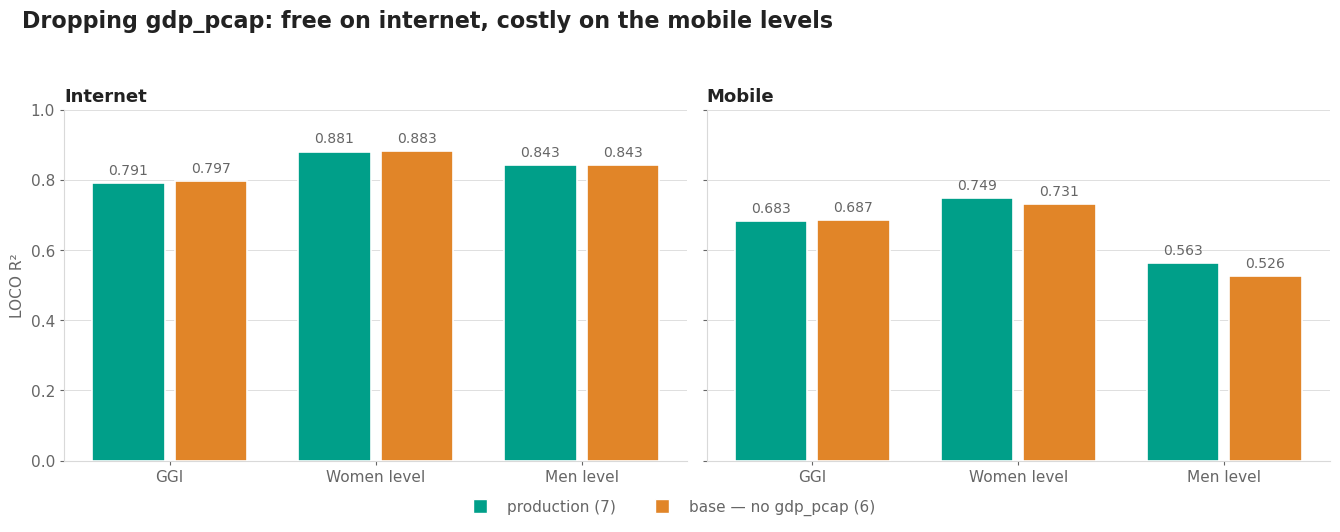

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5), sharey=True)

SERIES = list(MODELS)
COLOURS = {'production (7)': plot.PALETTE[0], 'base — no gdp_pcap (6)': plot.PALETTE[1]}

for ax, indicator in zip(axes, CFG['indicators']):
    block = drop_perf[drop_perf['indicator'] == indicator]
    table = block.pivot_table(index='outcome', columns='model', values='loco_r2').reindex(OUTCOMES)
    plot.grouped_bars(ax, [LABELS[o] for o in OUTCOMES], SERIES,
                      {s: table[s].to_numpy() for s in SERIES}, colours=COLOURS, fmt='{:.3f}')
    plot.tidy(ax, title=indicator.capitalize(), grid='y')
    ax.set_ylim(0, 1)

axes[0].set_ylabel('LOCO R²', fontsize=plot.STYLE['tick_fs'], color=plot.MUTED)
plot.legend(fig, [plot.swatch(COLOURS[s], s) for s in SERIES], y=-0.06)
plot.suptitle(fig, 'Dropping gdp_pcap: free on internet, costly on the mobile levels')
fig.tight_layout(rect=(0, 0, 1, 0.93))
plot.save(fig, NOTEBOOK, '1_drop_gdp_pcap')
plt.show()

## 3. Are the six that remain stable?

The same `robustipy` sweep as notebooks 14 and 15, with identical settings, now over the six
surviving terms: each in turn as the estimand, with every subset of the other five as controls —
6 focal variables × 2⁵ = 32 control combinations, per target.

The question this answers is not "does the model fit". It is whether a coefficient's **sign**
survives the choice of controls. D39 found the two sex-level Facebook terms flip sign in every
outcome they appear in while `fb_18_999_r` does not; the point of running it again without
`gdp_pcap` is to see whether the income term was the source of that instability or merely a
bystander.

In [5]:
def stability(data, outcome, focal, controls):
    """robustipy over every subset of `controls`, with `focal` as the estimand"""
    frame = data.dropna(subset=BASE_SPEC + [outcome])
    model = OLSRobust(y=[outcome], x=[focal], data=frame)
    # every argument is passed explicitly: robustipy prompts interactively for any it is not
    # given, which hangs a non-interactive run
    model.fit(controls=controls, draws=DRAWS, kfold=KFOLD, oos_metric=OOS_METRIC,
              seed=params.SEED, n_cpu=N_CPU, compute_shap=False)
    return model.get_results().summary_df


records, curves = [], []

for indicator, data in panels.items():
    for outcome_var in OUTCOMES:
        outcome = f'{indicator}_{outcome_var}'
        full = sm.OLS(data[outcome], sm.add_constant(data[BASE_SPEC]), missing='drop').fit()

        for focal in BASE_SPEC:
            summary = stability(data, outcome, focal, [c for c in BASE_SPEC if c != focal])
            median = summary['median']
            records.append({
                'indicator': indicator, 'outcome': outcome_var, 'focal': focal,
                'n_specs': len(summary),
                'base_coef': float(full.params[focal]),
                'base_p': float(full.pvalues[focal]),
                'median_coef': float(median.median()),
                'min_coef': float(summary['min'].min()),
                'max_coef': float(summary['max'].max()),
                'share_positive': float((median > 0).mean()),
                'sign_stable': bool((median > 0).all() or (median < 0).all()),
                'share_ci_excludes_0': float(((summary['ci_down'] > 0)
                                              | (summary['ci_up'] < 0)).mean()),
                'median_r2': float(summary['r2'].median()),
                'median_oos': float(summary['av_k_metric'].median()),
            })
            curves.append(summary.assign(indicator=indicator, outcome=outcome_var, focal=focal))

stability_summary = pd.DataFrame(records)
curve_data = pd.concat(curves, ignore_index=True)
print(f'\n{len(stability_summary)} focal-variable runs, {len(curve_data)} specifications total')
print(f"sign stable in {int(stability_summary['sign_stable'].sum())} of "
      f"{len(stability_summary)} runs")

OLSRobust is running with n_cpu=4, draws=100, folds=5, seed=42.
We're evaluating our out-of-sample predictions with the pseudo-r2 metric.
The estimand of interest is fb_18_999_men. Let's begin the calculations...
Total model runs: 3,200 (draws=100, control_specs=32, y_composites=1)


Bootstrap draws:   0.0%|          | 0/3200 [00:00<?, ?draw/s]

OLSRobust is running with n_cpu=4, draws=100, folds=5, seed=42.
We're evaluating our out-of-sample predictions with the pseudo-r2 metric.
The estimand of interest is fb_18_999_wom. Let's begin the calculations...
Total model runs: 3,200 (draws=100, control_specs=32, y_composites=1)


Bootstrap draws:   0.0%|          | 0/3200 [00:00<?, ?draw/s]

OLSRobust is running with n_cpu=4, draws=100, folds=5, seed=42.
We're evaluating our out-of-sample predictions with the pseudo-r2 metric.
The estimand of interest is fb_18_999_r. Let's begin the calculations...
Total model runs: 3,200 (draws=100, control_specs=32, y_composites=1)


...

OLSRobust is running with n_cpu=4, draws=100, folds=5, seed=42.
We're evaluating our out-of-sample predictions with the pseudo-r2 metric.
The estimand of interest is gdi. Let's begin the calculations...
Total model runs: 3,200 (draws=100, control_specs=32, y_composites=1)


Bootstrap draws:   0.0%|          | 0/3200 [00:00<?, ?draw/s]

OLSRobust is running with n_cpu=4, draws=100, folds=5, seed=42.
We're evaluating our out-of-sample predictions with the pseudo-r2 metric.
The estimand of interest is year. Let's begin the calculations...
Total model runs: 3,200 (draws=100, control_specs=32, y_composites=1)


Bootstrap draws:   0.0%|          | 0/3200 [00:00<?, ?draw/s]


36 focal-variable runs, 1152 specifications total
sign stable in 21 of 36 runs


In [6]:
stability_summary[['indicator', 'outcome', 'focal', 'base_coef', 'median_coef',
                   'min_coef', 'max_coef', 'sign_stable', 'share_positive',
                   'share_ci_excludes_0']].round(4)

,indicator,outcome,focal,base_coef,median_coef,min_coef,max_coef,sign_stable,share_positive,share_ci_excludes_0
0,internet,ggi,fb_18_999_men,0.7679,0.2982,-0.6120,1.3279,False,0.9375,0.8438
1,internet,ggi,fb_18_999_wom,-0.7217,0.2109,-1.3279,1.1727,False,0.6875,0.8125
2,internet,ggi,fb_18_999_r,0.5080,0.4558,-0.1800,1.2116,True,1.0000,0.9375
3,internet,ggi,hdi,0.3009,0.4428,-0.2064,1.3971,True,1.0000,0.8750
4,internet,ggi,gdi,1.3514,1.6677,0.2381,4.1552,True,1.0000,1.0000
5,internet,ggi,year,0.0093,0.0131,-0.0123,0.0799,True,1.0000,0.4062
6,internet,wom,fb_18_999_men,0.4723,0.3930,-0.7420,1.2332,False,0.9375,0.8750
7,internet,wom,fb_18_999_wom,-0.2869,0.2950,-0.8427,1.6120,False,0.7188,0.5938
8,internet,wom,fb_18_999_r,0.1359,0.2671,-0.4199,1.1495,False,0.9375,0.5000
9,internet,wom,hdi,1.1678,1.3215,0.7467,1.9708,True,1.0000,1.0000


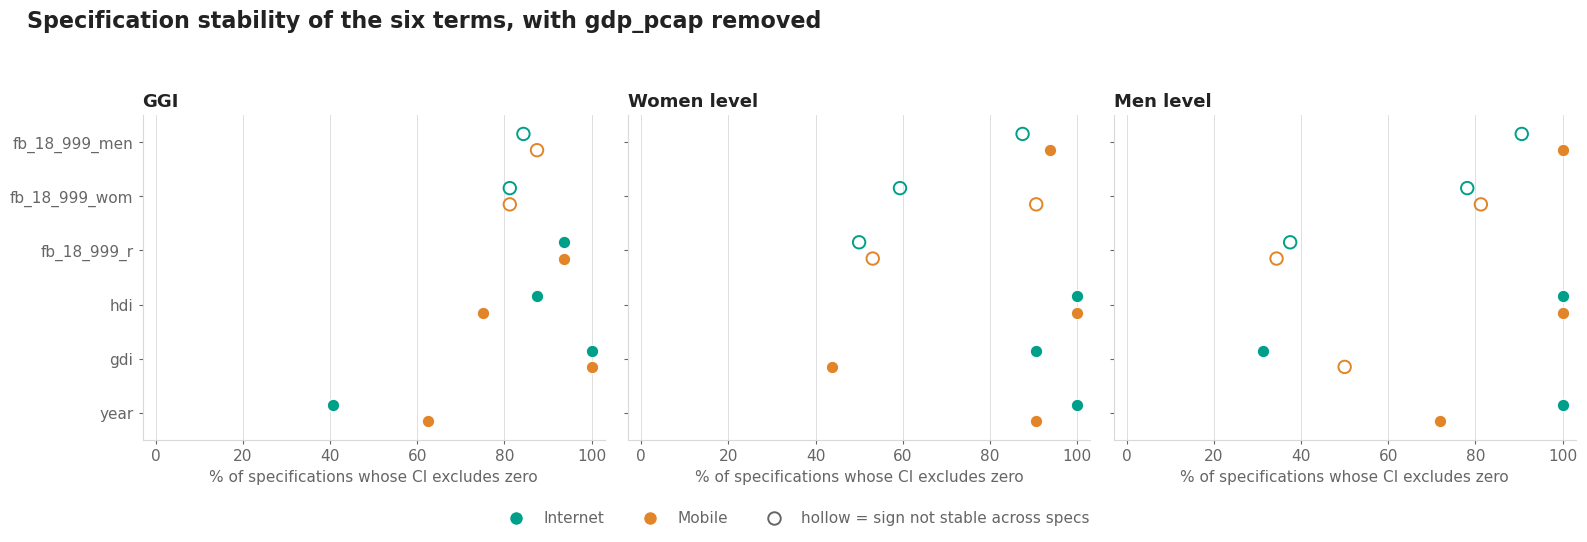

In [7]:
fig, axes = plt.subplots(1, len(OUTCOMES), figsize=(16, 5), sharey=True)

for ax, outcome_var in zip(np.atleast_1d(axes), OUTCOMES):
    block = stability_summary[stability_summary['outcome'] == outcome_var]
    y = np.arange(len(BASE_SPEC))
    for k, indicator in enumerate(CFG['indicators']):
        sub = block[block['indicator'] == indicator].set_index('focal').reindex(BASE_SPEC)
        offset = (k - 0.5) * 0.3
        # a hollow marker where the sign is not stable: the value is there, the claim is not
        for i, (_, r) in enumerate(sub.iterrows()):
            filled = bool(r['sign_stable'])
            ax.scatter(r['share_ci_excludes_0'] * 100, y[i] + offset, s=80,
                       facecolor=plot.PALETTE[k] if filled else 'none',
                       edgecolor=plot.PALETTE[k] if not filled else 'white',
                       linewidth=1.4 if not filled else 0.8, zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels(BASE_SPEC)
    ax.set_ylim(len(BASE_SPEC) - 0.5, -0.5)
    ax.set_xlim(-3, 103)
    plot.tidy(ax, title=LABELS[outcome_var],
              xlabel='% of specifications whose CI excludes zero', grid='x')

handles = [plot.swatch(plot.PALETTE[k], i.capitalize(), marker='o')
           for k, i in enumerate(CFG['indicators'])]
handles.append(plt.Line2D([], [], marker='o', linestyle='None', markersize=9,
                          markerfacecolor='none', markeredgecolor=plot.MUTED,
                          markeredgewidth=1.4, label='hollow = sign not stable across specs'))
plot.legend(fig, handles, y=-0.08)
plot.suptitle(fig, 'Specification stability of the six terms, with gdp_pcap removed')
fig.tight_layout(rect=(0, 0, 1, 0.92))
plot.save(fig, NOTEBOOK, '2_stability_without_gdp')
plt.show()

## 4. Substitutes and additions

Every one of the 46 candidates is tried in two arms, against all six targets:

| arm | specification | asks |
| --- | --- | --- |
| **substitute (7)** | `base (6) + X` | can X do `gdp_pcap`'s job better than `gdp_pcap`? |
| **augment (8)** | `production (7) + X` | is X just a good variable, regardless? |

Both are compared to **production (7)** on the same rows, so the difference in LOCO R² is the
quantity of interest throughout. A candidate that wins in the substitute arm *and* in the augment
arm is a good predictor that happens not to need `gdp_pcap` next to it. A candidate that wins only
in the substitute arm is the one the brief is really after: a genuine replacement.

In [8]:
arm_rows = []
for indicator, data in panels.items():
    for outcome_var in OUTCOMES:
        outcome = f'{indicator}_{outcome_var}'
        reference = production_loco.loc[(indicator, outcome_var)]

        arm_rows.append({'indicator': indicator, 'outcome': outcome_var, 'arm': 'base (6)',
                         'candidate': '(none)', **score(data, BASE_SPEC, outcome)})
        for candidate in CANDIDATES:
            arm_rows.append({'indicator': indicator, 'outcome': outcome_var,
                             'arm': 'substitute (7)', 'candidate': candidate,
                             **score(data, BASE_SPEC + [candidate], outcome)})
            arm_rows.append({'indicator': indicator, 'outcome': outcome_var,
                             'arm': 'augment (8)', 'candidate': candidate,
                             **score(data, PROD_SPEC + [candidate], outcome)})

arms = pd.DataFrame(arm_rows)
arms['vs_production'] = arms['loco_r2'] - pd.MultiIndex.from_frame(
    arms[['indicator', 'outcome']]).map(production_loco)

# sanity: the substitute arm with candidate == gdp_pcap IS production, so it must score identically
check = arms[(arms['arm'] == 'substitute (7)') & (arms['candidate'] == DROPPED)]
assert check['vs_production'].abs().max() < 1e-12, 'the substitute arm does not reproduce production'
print(f'{len(arms)} fits | identity check passed: substituting {DROPPED} back in reproduces '
      f'production exactly')

ranked = (arms[arms['arm'] == 'substitute (7)']
          .groupby('candidate')['vs_production']
          .agg(mean_gain='mean', worst='min', best='max',
               targets_improved=lambda s: int((s > 0).sum()))
          .sort_values('mean_gain', ascending=False))
ranked.insert(0, 'label', [CAND_LABEL.get(c, c) for c in ranked.index])
ranked.head(15).round(4)

534 fits | identity check passed: substituting gdp_pcap back in reproduces production exactly


,label,mean_gain,worst,best,targets_improved
candidate,,,,,
wdi_internet,Internet usage in the last 3 months,0.0211,0.0041,0.0383,6
pov_hr,Poverty headcount ratio at \n$2.15 a day (2017...,0.0068,-0.0095,0.0159,4
wdi_acel,Access to electricity (%),0.0055,-0.0145,0.0307,3
gdp_pcap,Logged GDP per capita,-0.0000,-0.0000,0.0000,3
wdi_unemp,Unemployment rate,-0.0013,-0.0428,0.0306,3
se_r,Population with at leat secondary eductions ratio,-0.0047,-0.0467,0.0317,3
wdi_litrad,Literacy rate,-0.0054,-0.0182,0.0067,1
le,Life expectancy at birth,-0.0059,-0.0371,0.0174,2
bicc_gmi,Global Militarization Index,-0.0061,-0.0386,0.0103,3


In [9]:
# the substitute arm, target by target, for the strongest candidates — a mean gain can hide a
# candidate that rescues one outcome and wrecks another, which is exactly what happens here
TOP_N = 10
top = list(ranked.head(TOP_N).index)

detail = (arms[(arms['arm'] == 'substitute (7)') & (arms['candidate'].isin(top))]
          .pivot_table(index='candidate', columns=['indicator', 'outcome'], values='vs_production')
          .reindex(top))
base_row = (arms[arms['arm'] == 'base (6)']
            .pivot_table(index='arm', columns=['indicator', 'outcome'], values='vs_production'))
detail = pd.concat([base_row.rename(index={'base (6)': '— drop, add nothing —'}), detail])
detail.round(3)

indicator             internet               mobile              
outcome                    ggi    men    wom    ggi    men    wom
— drop, add nothing —    0.006  0.001  0.002  0.004 -0.036 -0.018
wdi_internet             0.004  0.038  0.031  0.005  0.019  0.030
pov_hr                   0.016  0.015  0.014 -0.005  0.010 -0.009
wdi_acel                 0.031  0.014  0.012 -0.005 -0.005 -0.015
gdp_pcap                 0.000  0.000  0.000  0.000 -0.000  0.000
wdi_unemp                0.009 -0.002  0.000  0.031 -0.043 -0.002
se_r                     0.032  0.004  0.007 -0.000 -0.047 -0.025
wdi_litrad               0.007 -0.007 -0.004 -0.006 -0.004 -0.018
le                       0.002 -0.005 -0.002  0.017 -0.037 -0.011
bicc_gmi                 0.003  0.005  0.010 -0.002 -0.039 -0.015
eys                      0.007  0.007  0.009 -0.005 -0.036 -0.022

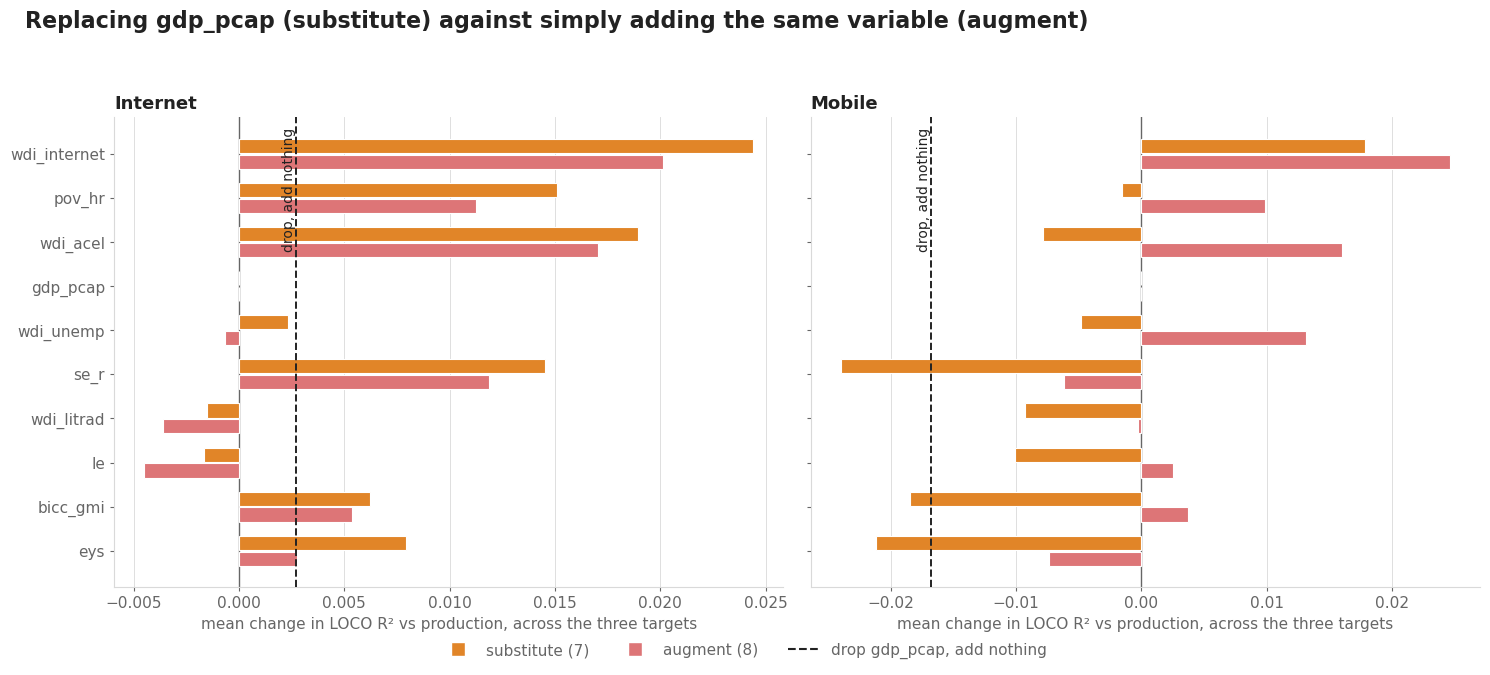

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)

ARM_COLOUR = {'substitute (7)': plot.PALETTE[1], 'augment (8)': plot.PALETTE[3]}
order = list(ranked.head(TOP_N).index)[::-1]
y = np.arange(len(order))

for ax, indicator in zip(axes, CFG['indicators']):
    for arm, colour in ARM_COLOUR.items():
        block = (arms[(arms['arm'] == arm) & (arms['indicator'] == indicator)
                      & (arms['candidate'].isin(order))]
                 .groupby('candidate')['vs_production'].mean().reindex(order))
        offset = 0.18 if arm == 'substitute (7)' else -0.18
        ax.barh(y + offset, block.to_numpy(), height=0.32, color=colour,
                edgecolor='white', linewidth=0.8, zorder=3)

    # the arm with no candidate at all, as the bar a substitute has to beat
    drop = (arms[(arms['arm'] == 'base (6)') & (arms['indicator'] == indicator)]
            ['vs_production'].mean())
    ax.axvline(drop, color=plot.INK, linewidth=1.4, linestyle='--', zorder=4)
    ax.annotate('drop, add nothing', (drop, len(order) - 0.4), rotation=90, ha='right',
                va='top', fontsize=plot.STYLE['tick_fs'] - 1, color=plot.INK)
    ax.axvline(0, color=plot.MUTED, linewidth=1, zorder=2)

    ax.set_yticks(y)
    ax.set_yticklabels(order)
    plot.tidy(ax, title=indicator.capitalize(),
              xlabel='mean change in LOCO R² vs production, across the three targets', grid='x')

plot.legend(fig, [plot.swatch(c, a) for a, c in ARM_COLOUR.items()]
            + [plt.Line2D([], [], color=plot.INK, linestyle='--', label='drop gdp_pcap, add nothing')],
            y=-0.04)
plot.suptitle(fig, 'Replacing gdp_pcap (substitute) against simply adding the same variable (augment)')
fig.tight_layout(rect=(0, 0, 1, 0.93))
plot.save(fig, NOTEBOOK, '3_substitutes_vs_augments')
plt.show()

### The leading candidate needs a provenance check before it is believed

`wdi_internet` — World Bank `IT.NET.USER.ZS`, *individuals using the internet, % of population* —
tops the substitute ranking. Before that is reported as a finding, note what it is: **the World Bank
series is compiled from ITU**, and **37 of the 108 internet rows in this panel are themselves ITU
observations**. On those rows the predictor and the outcome come from the same collection, by the
same statistical offices. That is not circularity in the abstract; it is shared provenance in the
concrete.

The correlations alone do not settle it — `wdi_internet` tracks the survey rows nearly as closely as
the ITU rows (0.842 vs 0.897 against the women's level). The decisive test is whether the *gain*
survives when the ITU rows are removed, which is what the cell below does.

In [11]:
SUSPECT = 'wdi_internet'

rows = []
for indicator, data in panels.items():
    itu = data[f'{indicator}_survey_type'].astype(str).str.contains('itu', case=False)
    for sample, frame in [('all rows', data), ('surveys only (ITU dropped)', data[~itu])]:
        for outcome_var in OUTCOMES:
            outcome = f'{indicator}_{outcome_var}'
            gain = (score(frame, BASE_SPEC + [SUSPECT], outcome)['loco_r2']
                    - score(frame, PROD_SPEC, outcome)['loco_r2'])
            rows.append({'indicator': indicator, 'sample': sample, 'n': len(frame),
                         'outcome': outcome_var, 'gain_vs_production': gain,
                         'corr_with_outcome': float(frame[SUSPECT].corr(frame[outcome]))})

provenance = pd.DataFrame(rows)
print(f'{SUSPECT} as a substitute — gain in LOCO R² over production\n')
print(provenance.pivot_table(index=['indicator', 'sample'], columns='outcome',
                             values='gain_vs_production').reindex(columns=OUTCOMES).round(3)
      .to_string())
print(f'\nITU rows in the internet panel: '
      f"{int(panels['internet']['internet_survey_type'].astype(str).str.contains('itu', case=False).sum())}"
      f" of {len(panels['internet'])}")

wdi_internet as a substitute — gain in LOCO R² over production

outcome                                 ggi    wom    men
indicator sample                                         
internet  all rows                    0.004  0.031  0.038
          surveys only (ITU dropped) -0.007  0.013  0.027
mobile    all rows                    0.005  0.030  0.019
          surveys only (ITU dropped) -0.002  0.015 -0.017

ITU rows in the internet panel: 37 of 108


## 5. What the sweep says

**`gdp_pcap` is free to drop on internet and not on mobile.** Removing it changes internet LOCO R²
by **+0.006 / +0.002 / +0.001** (GGI / women / men) — it was contributing nothing. On mobile it
splits: the GGI improves by +0.004, but the two levels lose **−0.018** and **−0.036**. The term earns
its place on exactly one thing, the mobile level models, and is dead weight everywhere else.

**Removing it does not buy stability, because it was never the problem.** Sign-stability rises only
from 22 of 42 runs in the seven-term production sweep (E5) to **21 of 36** here — 52% to 58%, which
is the arithmetic of deleting one unstable term, not a change of character. The pattern is unchanged:

| focal term | sign-stable across all 32 control sets |
| --- | --- |
| `hdi` | **6 of 6** |
| `year` | **6 of 6** |
| `gdi` | 5 of 6 |
| `fb_18_999_men` | 2 of 6 |
| `fb_18_999_r` | 2 of 6 |
| `fb_18_999_wom` | **0 of 6** |

**Fourteen of the fifteen unstable runs are a Facebook term**; the fifteenth is `gdi` on the mobile
men's level. The offline block is solid and the online block is not, exactly as D39 found with
`gdp_pcap` still in the model. `gdp_pcap` was a bystander to that instability, not its source, and
removing it does not address it.

**No candidate replaces it where it actually matters.** The mobile men's level is the one target that
depends on `gdp_pcap`, and among the ten strongest substitutes, five make it **worse than dropping
the income term altogether**: `se_r` −0.047, `wdi_unemp` −0.043, `bicc_gmi` −0.039, `le` −0.037,
`eys` −0.036, against −0.036 for having no income term at all. Only two improve it — `wdi_internet`
(+0.019) and `pov_hr` (+0.010). **Putting a different development measure in `gdp_pcap`'s slot is
mostly worse than putting nothing there**, which is the opposite of what the ranking's mean column
suggests, and the reason the per-target detail matters more than the ranking.

**The two candidates that look like genuine wins.**

- `wdi_acel` (access to electricity) — internet **+0.031 / +0.014 / +0.012**, mobile roughly neutral
  (−0.005 / −0.005 / −0.015). A clean infrastructure proxy with no provenance overlap with the
  outcome, and the best-behaved substitute in the pool.
- `se_r` (secondary-education sex ratio) — internet GGI **+0.032**, the largest single-target gain on
  the outcome the paper cares most about, but mobile men **−0.047**, the largest single-target loss
  in the table. Not a free choice.

**`wdi_internet` should not be adopted, despite topping the ranking on all six targets.** Its gain
roughly halves once the 37 ITU rows are removed and reverses sign on three targets (mobile men
+0.019 → **−0.017**; both GGIs go negative). The World Bank series `IT.NET.USER.ZS` is compiled from
ITU and **a third of the internet panel is ITU**, so a material part of the apparent improvement is
the predictor and the outcome sharing a source. A model whose purpose is to estimate internet
adoption where no measurement exists cannot lean on a national internet-adoption measurement.

**The honest summary.** The case for removing `gdp_pcap` is that it is inert (D44, D45) and mildly
unstable — not that something better exists. Nothing in a 46-variable pool replaces it on the one
target that needs it, and removing it leaves the real instability untouched. The realistic options
are: drop it and accept the mobile-level cost; keep it for the mobile levels only, at the price of an
outcome-dependent specification; or add `wdi_acel` alongside it and re-test, which is the augment arm.


## 6. Write the tables

In [12]:
stamp = f'{datetime.now():%Y%m%d}'
for name, frame in [('drop_gdp_performance', drop_perf),
                    ('candidate_arms', arms),
                    ('candidate_ranking', ranked.reset_index()),
                    ('stability_without_gdp', stability_summary),
                    ('stability_curves', curve_data),
                    ('wdi_internet_provenance', provenance)]:
    path = params.table_dir(NOTEBOOK) / f'{name}_{stamp}.csv'
    frame.to_csv(path, index=False)
    print(f'{path.name:44s} {len(frame):6d} rows')

drop_gdp_performance_20260821.csv                12 rows
candidate_arms_20260821.csv                     534 rows
candidate_ranking_20260821.csv                   44 rows
stability_without_gdp_20260821.csv               36 rows
stability_curves_20260821.csv                  1152 rows
wdi_internet_provenance_20260821.csv             12 rows


## Notes

- **Nothing here is a proposal.** No production artefact is touched. The specification question this
  opens — whether `gdp_pcap` should stay — needs the mobile-level cost weighed against the
  instability, and that is a judgement, not a metric.
- **The sample is the unrefreshed panel** (108 / 99), matching notebooks 14 and 15. Notebook 13's
  extended panel and the refreshed offline predictors are separate changes; combining them with a
  specification change would make any result unattributable.
- **Candidate completeness is manufactured.** All 46 indicators are complete on every row only
  because `scripts/predictors.py` fills gaps with continent means before the panel is written. A
  heavily imputed variable can look well-behaved here for reasons that have nothing to do with the
  country it is standing in for. The imputation share is not carried on the panel, so it cannot be
  reported per candidate — this is the largest untested assumption in the notebook.
- **`pov_hr` ranks second and cannot be refreshed.** The World Bank rebased the poverty line from
  $2.15/2017 PPP to $3.00/2021 PPP, which is why `05_offline_predictors_update.py` deliberately
  excludes it (D40). It is frozen at the old definition, so a specification depending on it could not
  be carried forward to new years.
- **`robustipy` scores out-of-sample by k-fold**, holding out random rows; LOCO holds out a country.
  `av_k_metric` and `loco_r2` are never compared here.
- Companion notebooks: `14_specification_stability.ipynb` (production spec, all 127 subsets),
  `15_experimental_model_design.ipynb` (the same exercise for the Facebook terms). Decisions are
  recorded in `doc/decisions_exploration.md`.